# บทที่ 11 การจัดการสิ่งผิดปรกติ

**รายวิชา:** การเขียนโปรแกรมด้วยภาษาไพธอน 3
**ผู้สอน:** ผศ.พิศาล สุขขี
สาขาวิชาวิทยาการคอมพิวเตอร์ คณะศิลปศาสตร์และวิทยาศาสตร์ มหาวิทยาลัยราชภัฏศรีสะเกษ

---

ในการพัฒนาโปรแกรม **การจัดการสิ่งผิดปรกติ (Exception Handling)** ที่อาจเกิดขึ้นระหว่างโปรแกรมทำงานเป็นสิ่งที่นักพัฒนาต้องให้ความสำคัญ เพราะสิ่งผิดปรกติเกิดขึ้นได้ตลอดเวลา บางอย่างอาจ

- ทำให้โปรแกรม **หยุดทำงานกลางคัน** (เช่น ผู้ใช้ป้อนตัวอักษรแทนตัวเลข)
- ส่งผลเสียต่อเครื่องคอมพิวเตอร์หรือข้อมูล (เช่น เขียนไฟล์ค้างไว้ครึ่งเดียว)
- ทำให้ได้ **ผลลัพธ์ผิดพลาด** ไม่สอดคล้องกับข้อมูลอินพุต

ภาษาโปรแกรมสมัยใหม่รวมทั้งไพธอน จึงมีกลไกสำหรับ **ตรวจจับและควบคุม** สิ่งผิดปรกติ ให้โปรแกรมดำเนินต่อไปในทิศทางที่กำหนดไว้ได้ โดยไม่ต้องหยุดทำงานทุกครั้งที่มีสิ่งผิดปรกติเกิดขึ้น

### 🎯 วัตถุประสงค์การเรียนรู้
เมื่อศึกษาบทเรียนนี้จบ ผู้เรียนจะสามารถ
1. อธิบายความแตกต่างระหว่าง Errors (ข้อผิดพลาดทางไวยากรณ์) และ Exceptions (สิ่งผิดปรกติขณะทำงาน) ได้
2. อ่าน Traceback และระบุชนิดของ Exception ที่พบบ่อยได้
3. ใช้คำสั่ง `try-except` ตรวจจับ Exception ชนิดเดียว หลายชนิด และทั้งหมดได้
4. อธิบายและใช้ประโยค `else` และ `finally` ได้ถูกต้อง
5. 🆕 สร้าง Exception เองด้วยคำสั่ง `raise` เพื่อตรวจสอบความถูกต้องของข้อมูลได้

### 📖 วิธีใช้ Notebook นี้
- กด **Shift + Enter** ที่เซลล์โค้ดเพื่อรัน โดยรันเรียงจากบนลงล่าง
- เซลล์ที่มีเครื่องหมาย **⌨️ (โต้ตอบ)** ใช้ `input()` รอรับค่าจากแป้นพิมพ์ ให้ลองป้อนทั้งค่าที่ถูกต้องและค่าที่ผิด แล้วสังเกตผล
- ตัวอย่างที่ตั้งใจให้เกิด Exception ใน Notebook นี้ใช้ฟังก์ชัน `demo()` แสดง Traceback โดยไม่ทำให้ Notebook หยุด (ถ้าอยากเห็นของจริง ให้พิมพ์โค้ดนั้นในเซลล์ใหม่แล้วรัน)
- กล่อง **🧠 ตรวจสอบความเข้าใจ** ให้คิดก่อนเปิดเฉลย กล่อง **✍️ ลงมือทำ** มีเซลล์ตรวจคำตอบอัตโนมัติ และกล่อง **🆕** คือข้อแก้ไขหรือเนื้อหาเสริมจากเอกสาร

## 📑 สารบัญ
- [11.1 ความหมายของสิ่งผิดปรกติ](#s111) · Errors · Exceptions
- [11.2 สิ่งผิดปรกติในภาษาไพธอน](#s112) · 🆕 การอ่าน Traceback · ตารางที่ 11.1 · 🆕 ลำดับชั้นของ Exception · ✍️ แบบฝึก 11.1
- [11.3 การตรวจจับและควบคุมสิ่งผิดปรกติ](#s113)
  - [11.3.1 try-except](#s1131) · ✍️ แบบฝึก 11.2
  - [11.3.2 การตรวจจับหลายประเภท](#s1132)
  - [11.3.3 การจัดการสิ่งผิดปรกติทั้งหมด](#s1133) · ✍️ แบบฝึก 11.3
  - [11.3.4 ประโยค else](#s1134)
  - [11.3.5 ประโยค finally](#s1135) · ✍️ แบบฝึก 11.4
  - [🆕 11.3.6 การสร้างสิ่งผิดปรกติด้วย raise](#s1136) · ✍️ แบบฝึก 11.5
- [11.4 สรุป](#s114)
- [11.5 คำถามท้ายบท](#s115) · 🏆 แบบทดสอบ
- [11.6 บรรณานุกรม](#s116)

### 🧰 เตรียมเครื่องมือ
รันเซลล์ด้านล่างก่อน ฟังก์ชัน `demo(โค้ด)` จะรันโค้ดที่ส่งให้ แล้วแสดงผลลัพธ์หรือ Traceback แบบเดียวกับที่เห็นในโหมดโต้ตอบ (`>>>`) ของไพธอน

In [ ]:
import traceback, sys

def demo(src, env=None):
    # รันโค้ดแบบโหมดโต้ตอบ: แสดงผลลัพธ์ หรือแสดง Traceback โดยไม่ทำให้ Notebook หยุด
    env = globals() if env is None else env
    print(">>>", src.replace("\n", "\n... "))
    try:
        try:
            result = eval(compile(src, "<stdin>", "eval"), env)
            if result is not None:
                print(repr(result))
        except SyntaxError:
            exec(compile(src, "<stdin>", "exec"), env)
    except SyntaxError as e:
        print("".join(traceback.format_exception_only(type(e), e)).rstrip())
    except Exception as e:
        print("Traceback (most recent call last):")
        print('  File "<stdin>", line 1, in <module>')
        print(f"{type(e).__name__}: {e}")
    print()

demo("1 + 1")

<a id="s111"></a>
## 11.1 ความหมายของสิ่งผิดปรกติ

ก่อนเรียนวิธีจัดการ ต้องแยกให้ออกระหว่าง **ข้อผิดพลาด (Errors)** และ **สิ่งผิดปรกติ (Exceptions)**

### 11.1.1 Errors
ในบริบทของการพัฒนาซอฟต์แวร์ **Errors** คือข้อผิดพลาดเกี่ยวกับ **หลักไวยากรณ์** หรือข้อกำหนดของภาษา เช่น ลืมเครื่องหมาย `:` วงเล็บไม่ครบคู่ ย่อหน้าไม่ถูกต้อง ตัวแปลภาษาจะตรวจพบ **ก่อน** โปรแกรมเริ่มทำงาน และ **ไม่ยอมให้โปรแกรมเริ่มทำงาน** จนกว่าจะแก้ไขให้ถูกต้อง

### 11.1.2 Exceptions
**Exceptions** คือสิ่งผิดปรกติที่เกิดขึ้น **ระหว่างการทำงาน** ของโปรแกรม เมื่อมีบางอย่างที่ไม่คาดคิดทำให้ทำงานตามปกติต่อไม่ได้ ไวยากรณ์ของโปรแกรมถูกต้องทุกอย่าง แต่ **ข้อมูลหรือสถานการณ์ขณะทำงาน** ไม่เป็นไปตามที่คาดไว้ และถ้าไม่จัดการ Exception อย่างถูกต้อง โปรแกรมจะ **หยุดทำงานทันที** เพราะไม่รู้ว่าต้องทำอย่างไรต่อ

| | Errors (Syntax Errors) | Exceptions |
|---|---|---|
| เกิดเมื่อใด | ก่อนโปรแกรมทำงาน (ตอนแปลงโค้ด) | ระหว่างโปรแกรมทำงาน |
| สาเหตุ | เขียนผิดไวยากรณ์ | ข้อมูล/สถานการณ์ไม่คาดคิด เช่น หารด้วย 0, ไม่พบไฟล์ |
| โปรแกรมเริ่มทำงานได้ไหม | ❌ ไม่ได้เลยแม้แต่บรรทัดแรก | ✅ ทำงานได้จนถึงจุดที่เกิด |
| วิธีแก้ | แก้โค้ดให้ถูกไวยากรณ์ | แก้โค้ด หรือ **ตรวจจับและจัดการ** ด้วย `try-except` |

**ตัวอย่างจากเอกสาร** โปรแกรมขอให้ผู้ใช้ป้อนตัวเลข แล้วนำ 50 ไปหารด้วยตัวเลขนั้น วนซ้ำไปเรื่อย ๆ

In [ ]:
# ⌨️ (โต้ตอบ) โปรแกรมจากเอกสาร — ลองป้อน 5, -2, 0, abc, 2.5
# เป็นลูปไม่สิ้นสุด: จะหยุดเมื่อเกิด Exception (หรือกดปุ่ม ■ Interrupt)
keep_asking = True

while keep_asking:
    x = int(input("Enter a number: "))
    print("Dividing 50 by", x, "will give you :", 50/x)

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 ข้อแก้ไข: ชนิดของ Exception ในตัวอย่างนี้
เอกสารกล่าวว่าเมื่อผู้ใช้ป้อนสตริงแทนตัวเลขจะเกิด `TypeError` แต่ในย่อหน้าถัดมากล่าวว่าเกิด `ValueError` — **ที่ถูกต้องคือ `ValueError`** เพราะ `int("abc")` รับสตริงได้ (ชนิดถูก) แต่ค่าในสตริงแปลงเป็นจำนวนเต็มไม่ได้ (ค่าไม่เหมาะสม)

นอกจากนี้ เอกสารกล่าวว่า "ป้อนจำนวนเต็มมากกว่า 0 โปรแกรมจะทำงานถูกต้อง" ที่จริง **จำนวนเต็มลบก็ทำงานได้** มีเพียง **0** เท่านั้นที่ทำให้เกิด `ZeroDivisionError`

| ค่าที่ป้อน | ผลลัพธ์ |
|---|---|
| `5` หรือ `-2` | ทำงานปกติ |
| `0` | `ZeroDivisionError: division by zero` |
| `abc` หรือ `2.5` | `ValueError: invalid literal for int() with base 10: ...` |
</div>

In [ ]:
demo("50 / int('5')")
demo("50 / int('-2')")
demo("50 / int('0')")
demo("50 / int('abc')")
demo("50 / int('2.5')")

<a id="s112"></a>
## 11.2 สิ่งผิดปรกติในภาษาไพธอน

ถ้าผู้เรียนเคยรันโปรแกรมในบทก่อน ๆ แล้วโปรแกรม "ขัดข้อง" เช่น รับข้อมูลผิดประเภท หรือหารด้วย 0 จะเห็นข้อความ **Traceback** ปรากฏขึ้น พร้อมข้อมูลวินิจฉัยมากที่สุดเท่าที่ตัวแปลภาษาจะให้ได้ ได้แก่ **ชื่อของสิ่งผิดปรกติ เหตุผล และหมายเลขบรรทัด** ที่เกิด

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 วิธีอ่าน Traceback
```
Traceback (most recent call last):          ← ลำดับการเรียก (ล่าสุดอยู่ล่างสุด)
  File "score.py", line 7, in <module>      ← ไฟล์และบรรทัดที่เรียก
    total = add_score(s)
  File "score.py", line 3, in add_score     ← บรรทัดที่เกิดปัญหาจริง
    return 10 + s
TypeError: unsupported operand type(s) for +: 'int' and 'str'
└─ชนิด──┘ └──────────── เหตุผล ──────────────────────────────┘
```
**อ่านจากล่างขึ้นบน:** บรรทัดสุดท้ายบอก *ชนิด* และ *เหตุผล* บรรทัดเหนือขึ้นไปบอก *ตำแหน่ง* ที่เกิด
</div>

ต่อไปนี้คือตัวอย่างสิ่งผิดปรกติที่พบบ่อย

**`NameError`** — อ้างถึงตัวแปรที่ยังไม่ได้กำหนดค่า (uninitialized) ซึ่งไม่พบในตารางสัญลักษณ์ของไพธอน

In [ ]:
demo("foo")

**`ZeroDivisionError`** — ตัวหารมีค่าเป็นศูนย์

In [ ]:
demo("1/0")

**`SyntaxError`** — เขียนผิดหลักไวยากรณ์ เกิดขึ้นตอนที่ไพธอน **แปลงซอร์สโค้ดเป็นไบต์โค้ด (bytecode)** ก่อนเริ่มทำงาน จึงไม่ได้เกิดขณะดำเนินการ และต้องแก้ไขก่อนจึงจะรันได้

In [ ]:
demo("for")

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 หมายเหตุ: SyntaxError ไม่ใช่ชนิดเดียวที่เกิดก่อนทำงาน
เอกสารกล่าวว่า `SyntaxError` เป็นสิ่งผิดปรกติ "เดียว" ที่ไม่ได้เกิดขณะดำเนินการ ที่จริงยังมี **`IndentationError`** และ `TabError` (ย่อหน้าผิด) ซึ่งเป็นชนิดย่อยของ `SyntaxError` ด้วย และในกรณีพิเศษ `SyntaxError` ก็เกิดขณะทำงานได้ เช่น เมื่อเรียก `eval()`/`exec()` หรือ `import` ไฟล์ที่เขียนผิดไวยากรณ์ (อย่างฟังก์ชัน `demo` ของเรานี่เอง)
</div>

In [ ]:
demo("if True:\nprint('no indent')")

**`IndexError`** — เข้าถึงดัชนีที่อยู่นอกช่วงของข้อมูลแบบลำดับ (ลิสต์ ทูเพิล สตริง)

In [ ]:
aList = []
demo("aList[0]")

**`KeyError`** — ขอข้อมูลจากดิกชันนารีด้วย **คีย์ที่ไม่มีอยู่**

In [ ]:
aDict = {'host': 'earth', 'port': 80}
demo("aDict['server']")

**`FileNotFoundError`** — เปิดไฟล์ที่ไม่มีอยู่จริงบนดิสก์ เป็นตัวอย่างหนึ่งของสิ่งผิดปรกติเกี่ยวกับ **อินพุต/เอาต์พุต (I/O)** ของระบบปฏิบัติการ

In [ ]:
demo("open('blah')")

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 ข้อแก้ไข: IOError ในไพธอน 3
เอกสารกล่าวว่าสิ่งผิดปรกติประเภท I/O ทำให้เกิด `IOError` ซึ่งเป็นชื่อจากไพธอน 2 ในไพธอน 3
- `IOError` เป็นเพียง **ชื่อเรียกอื่น (alias)** ของ **`OSError`**
- ไพธอน 3 แยกเป็นชนิดย่อยที่เจาะจงขึ้น เช่น `FileNotFoundError` (ไม่พบไฟล์), `FileExistsError` (มีไฟล์อยู่แล้ว), `PermissionError` (ไม่มีสิทธิ์), `IsADirectoryError` (เปิดไดเรกทอรีเหมือนเป็นไฟล์)

ดังนั้น `except IOError:` ในเอกสารยังใช้ได้ (จับ `FileNotFoundError` ได้เพราะเป็นชนิดย่อย) แต่โค้ดสมัยใหม่นิยมเขียน `except FileNotFoundError:` หรือ `except OSError:`
</div>

In [ ]:
print("IOError is OSError ?", IOError is OSError)
print("FileNotFoundError เป็นชนิดย่อยของ OSError ?", issubclass(FileNotFoundError, OSError))

**`AttributeError`** — อ้างถึง **แอตทริบิวต์** ที่ไม่มีอยู่ในออบเจกต์ (เรื่องคลาสและออบเจกต์จะเรียนละเอียดในบทที่ 12)

In [ ]:
class myClass(object):
    pass

myInst = myClass()
myInst.bar = 'spam'
demo("myInst.bar")
demo("myInst.foo")

ออบเจกต์ `myInst` มีแอตทริบิวต์ `bar` ที่กำหนดค่าไว้แล้ว จึงเข้าถึงได้ตามปกติ แต่เมื่อเข้าถึงแอตทริบิวต์ **`foo`** ซึ่งไม่มีอยู่จริง จะเกิด `AttributeError` (🆕 เอกสารพิมพ์ว่า "เข้าถึงแอตทริบิวต์ `bar` ซึ่งไม่มีอยู่จริง" ที่ถูกคือ `foo`)

🆕 **`TypeError` และ `ValueError`** — คู่ที่สับสนบ่อยที่สุด

In [ ]:
demo("'5' + 3")          # TypeError: ชนิดข้อมูลใช้ร่วมกันไม่ได้
demo("len(42)")          # TypeError: ฟังก์ชันไม่รองรับชนิดนี้
demo("int('สิบ')")       # ValueError: ชนิดถูก (สตริง) แต่ค่าไม่เหมาะสม
demo("int('3.5')")       # ValueError

**ตารางที่ 11.1** Exceptions ที่พบบ่อยจากการทำงานของโปรแกรม

| ประเภทของ Exception | รายละเอียด | ตัวอย่างที่ทำให้เกิด |
|---|---|---|
| `AttributeError` | อ้างอิงแอตทริบิวต์ล้มเหลว | `"abc".push(1)` |
| `IOError` → 🆕 `OSError` / `FileNotFoundError` | เปิดไฟล์ที่ไม่มีอยู่ หรือ I/O ล้มเหลว | `open("ไม่มี.txt")` |
| `IndexError` | ใช้ดัชนีที่ไม่มีอยู่ในลำดับ | `[1, 2][5]` |
| `KeyError` | ใช้คีย์ที่ไม่มีอยู่ในดิกชันนารี | `{"a": 1}["b"]` |
| `NameError` | ไม่พบชื่อตัวแปรที่อ้างถึง | `print(scroe)` |
| `SyntaxError` | ไวยากรณ์ไม่ถูกต้อง | `if x > 1 print(x)` |
| `TypeError` | ดำเนินการกับข้อมูลผิดประเภท | `"5" + 3` |
| `ValueError` | ชนิดข้อมูลถูกต้องแต่ค่าไม่เหมาะสม | `int("abc")` |
| `ZeroDivisionError` | ตัวหารมีค่าเป็นศูนย์ | `10 / 0`, `10 % 0` |

### 🆕 ลำดับชั้นของ Exception (Exception Hierarchy)
Exception ในไพธอนเป็น **คลาส** ที่สืบทอดกันเป็นลำดับชั้น ทุกชนิดที่เราจะจัดการมีบรรพบุรุษร่วมกันคือ **`Exception`** ความรู้นี้สำคัญเพราะ `except X:` จะจับ **X และชนิดย่อยทั้งหมดของ X** ด้วย

<p align="center">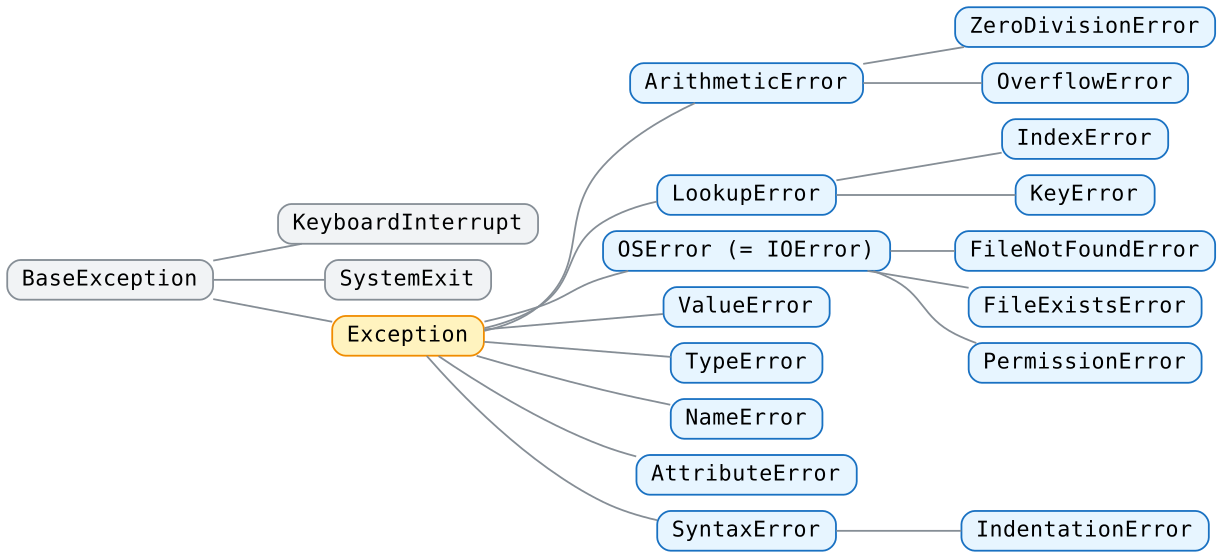<br><b>แผนภาพ</b> ลำดับชั้นของ Exception ที่พบบ่อย (บางส่วน)</p>

- `except LookupError:` จับได้ทั้ง `IndexError` และ `KeyError`
- `except OSError:` จับได้ทั้ง `FileNotFoundError`, `PermissionError`, ...
- `KeyboardInterrupt` (กด Ctrl+C) และ `SystemExit` **ไม่ใช่** ลูกของ `Exception` จึงไม่ถูก `except Exception:` จับ — ทำให้ยังหยุดโปรแกรมได้เสมอ

In [ ]:
print(ZeroDivisionError.__mro__)
print("KeyError เป็นชนิดย่อยของ LookupError ?", issubclass(KeyError, LookupError))
print("KeyboardInterrupt เป็นชนิดย่อยของ Exception ?", issubclass(KeyboardInterrupt, Exception))

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ แบบฝึก 11.1 — ทายชนิดของ Exception
แต่ละข้อในดิกชันนารี `answers` คือโค้ดหนึ่งบรรทัด จงเติม **ชื่อ Exception** ที่จะเกิดขึ้น (เป็นสตริง เช่น `"ValueError"`) ถ้าคิดว่า **ไม่เกิด Exception** ให้เติม `"OK"`

**อย่าเพิ่งรันโค้ดเหล่านั้น** ให้คิดเองก่อน แล้วรันเซลล์ตรวจคำตอบ
</div>

In [ ]:
answers = {
    "int('12a')":                 "",
    "[10, 20, 30][3]":            "",
    "{'a': 1}['A']":              "",
    "'Python' * 2":               "",
    "'Python' - 'P'":             "",
    "10 % 0":                     "",
    "float('3.14')":              "",
    "undefined_var + 1":          "",
    "'abc'.upper().reverse()":    "",
    "open('no_such_file.txt')":   "",
}

In [ ]:
# ✅ เซลล์ตรวจคำตอบ (รันได้ซ้ำ ไม่ต้องแก้ไข)
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as e:
        return f"Error → {type(e).__name__}: {e}"
def _raises(f, *a):
    try:
        r = f(*a)
    except Exception as e:
        return type(e).__name__
    return f"ไม่เกิด Exception (คืนค่า {r!r})"
def _eq(a, b):
    try:
        return a == b
    except Exception:
        return False
_tests = [(code_, answers.get(code_, ""), (lambda c: (lambda r: "OK" if r.startswith("ไม่เกิด") else r)(_raises(lambda: eval(c, {}))))(code_)) for code_ in answers]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = bool(_eq(_got, _exp))
    _ok += _pass
    _show = repr(_got)
    _show = _show if len(_show) < 80 else _show[:77] + "..."
    print(("✅ " if _pass else "❌ ") + _label + " = " + _show + ("" if _pass else ("\n      ควรได้ " + repr(_exp))[:240]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary>💡 ดูเฉลยแบบฝึก 11.1</summary>

| โค้ด | ผล | เหตุผล |
|---|---|---|
| `int('12a')` | `ValueError` | สตริงแปลงเป็นจำนวนเต็มไม่ได้ |
| `[10, 20, 30][3]` | `IndexError` | ดัชนีสูงสุดคือ 2 |
| `{'a': 1}['A']` | `KeyError` | คีย์แยกตัวพิมพ์เล็ก/ใหญ่ |
| `'Python' * 2` | `OK` | ได้ `'PythonPython'` |
| `'Python' - 'P'` | `TypeError` | สตริงไม่รองรับการลบ |
| `10 % 0` | `ZeroDivisionError` | มอดูโลด้วย 0 ก็คือการหารด้วย 0 |
| `float('3.14')` | `OK` | ได้ `3.14` |
| `undefined_var + 1` | `NameError` | ไม่มีตัวแปรนี้ |
| `'abc'.upper().reverse()` | `AttributeError` | สตริงไม่มีเมธอด `reverse` (มีเฉพาะลิสต์) |
| `open('no_such_file.txt')` | `FileNotFoundError` | ไม่มีไฟล์ |
</details>

<a id="s113"></a>
## 11.3 การตรวจจับและควบคุมสิ่งผิดปรกติ

**การตรวจจับและควบคุมสิ่งผิดปรกติ (Detecting and Handling Exceptions)** ทำได้โดยนำโค้ดที่ **อาจ** เกิดสิ่งผิดปรกติไปไว้ในบล็อกของคำสั่ง **`try`** ซึ่งทำหน้าที่เฝ้าดูสิ่งผิดปรกติระหว่างโปรแกรมทำงาน คำสั่ง `try` มี 2 รูปแบบหลัก ใช้แบบใดแบบหนึ่งหรือผสมกันก็ได้

| รูปแบบ | หน้าที่ |
|---|---|
| `try-except` | **ตรวจจับและจัดการ** สิ่งผิดปรกติ — ถ้าเกิด Exception ที่ตรงกับ `except` จะทำคำสั่งใน `except` แล้วโปรแกรมทำงานต่อได้ |
| `try-finally` | **ไม่ได้จัดการ** สิ่งผิดปรกติ แต่รับประกันว่าคำสั่งใน `finally` (เช่น ปิดไฟล์ คืนทรัพยากร) **ทำเสมอ** ไม่ว่าจะเกิด Exception หรือไม่ |
| `try-except-else-finally` | รูปแบบเต็ม (หัวข้อ 11.3.4–11.3.5) |

<p align="center">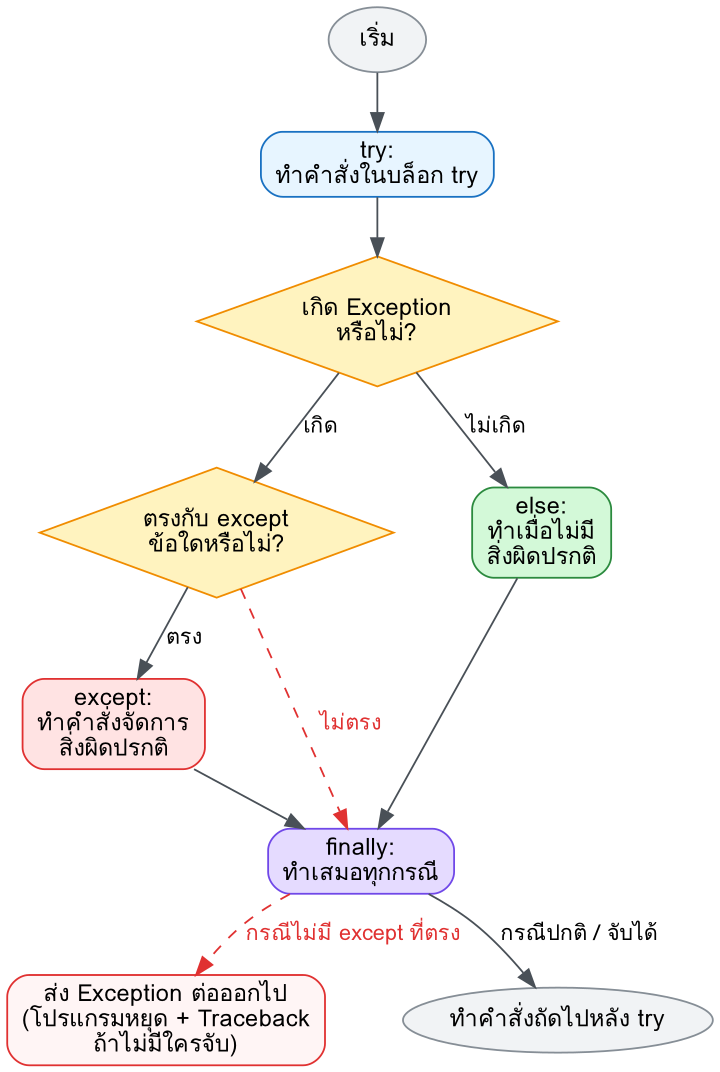<br><b>แผนภาพ</b> ลำดับการทำงานของ try / except / else / finally</p>

<a id="s1131"></a>
### 11.3.1 คำสั่ง try-except

ไวยากรณ์ในเอกสาร (รูปแบบจากหนังสือยุคไพธอน 2)
```
try:
    try_suite      # watch for exceptions here
except Exception[, reason]:
    except_suite   # exception-handling code
```

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 ไวยากรณ์ try-except ในไพธอน 3
รูปแบบ `except Exception, reason:` **ใช้ไม่ได้ในไพธอน 3** (เป็น `SyntaxError`) ต้องใช้คำว่า **`as`**

```python
try:
    คำสั่งที่อาจเกิดสิ่งผิดปรกติ
except ชนิดของException as ตัวแปร:     # "as ตัวแปร" ใส่หรือไม่ก็ได้
    คำสั่งจัดการสิ่งผิดปรกติ             # ตัวแปรเก็บออบเจกต์ Exception (ข้อความ เหตุผล)
```
</div>

**ตัวอย่าง: เปิดไฟล์ที่ไม่มีอยู่จริง** — ถ้าไม่มี `try-except` ไพธอนจะแจ้งข้อผิดพลาดและหยุดทันที แต่เมื่อครอบด้วย `try-except` เมื่อพบสิ่งผิดปรกติที่ตรงกับ `IOError` จะทำคำสั่งใน `except` แล้ว **โปรแกรมยังทำงานต่อไป**

In [ ]:
try:
    f = open('blah', 'r')
except IOError as e:
    print('Could not open file: ', e)

print("โปรแกรมยังทำงานต่อได้ ✔")

**ตัวอย่าง: รับคะแนนจากแป้นพิมพ์** บรรทัดที่ 3 แปลงสตริงเป็นจำนวนเต็ม ถ้าผู้ใช้ป้อนตัวอักษรจะเกิด `ValueError` ตรงบรรทัดนั้น เราจึงครอบด้วย `try-except`

In [ ]:
# ⌨️ (โต้ตอบ) ลองป้อน 85, 40 และ a
inp = input("Enter your score: ")
try:
    inp = int(inp)
    if inp > 80:
        print("Your score is pass")
    else:
        print("Your score is fail")
except ValueError as e:
    print("Your score must be int, ", e)

**ตัวอย่าง: วนรับคะแนนไปเรื่อย ๆ** เป็นการวนซ้ำแบบไม่สิ้นสุด (Infinite Loop) ผู้ใช้สั่งหยุดได้ด้วยการป้อน `q` ถ้าป้อนข้อมูลที่ไม่ใช่จำนวนเต็ม จะเกิด `ValueError` ที่บรรทัด `inp = int(inp)` แต่ถูก `except` จับไว้ พิมพ์ข้อความเตือน แล้ว `continue` กลับไปรับค่าใหม่ **โปรแกรมไม่หยุดชะงัก**

In [ ]:
# ⌨️ (โต้ตอบ) ลองป้อน 88, a, 95, 58 แล้วปิดด้วย q
while True:
    inp = input("Enter your score: ")

    if inp == 'q':
        print("Exit program")
        break

    try:
        inp = int(inp)
    except ValueError as e:
        print("Your score must be int, ", e)
        continue

    if inp > 90:
        print("Your score is pass")
    else:
        print("Your score is fail")

💡 สังเกตว่าเกณฑ์ผ่านในตัวอย่างแรกของเอกสารคือ `> 80` ส่วนตัวอย่างนี้คือ `> 90` (ทั้งสองแบบทำงานได้ เป็นเพียงตัวอย่าง)

🆕 **แบบจำลอง (ไม่ต้องป้อนค่า):** แปลงโปรแกรมข้างบนเป็นฟังก์ชันที่รับลิสต์ของอินพุตแทนการพิมพ์ เพื่อดูผลทุกกรณีพร้อมกัน

In [ ]:
def score_loop(entries):
    for inp in entries:
        print("Enter your score:", inp)
        if inp == 'q':
            print("Exit program")
            break
        try:
            inp = int(inp)
        except ValueError as e:
            print("Your score must be int, ", e)
            continue
        print("Your score is pass" if inp > 90 else "Your score is fail")

score_loop(["88", "a", "95", "58", "q", "ไม่ถูกอ่านเพราะ break แล้ว"])

<div style="border-left:5px solid #2b8a3e;padding:8px 14px;background:rgba(43,138,62,.08)">

### 🧠 ตรวจสอบความเข้าใจ 11.3.1
ผลลัพธ์ของโค้ดนี้คืออะไร
```python
try:
    print("A")
    x = int("12x")
    print("B")
except ValueError:
    print("C")
print("D")
```
<details><summary>เฉลย</summary>

```
A
C
D
```
เมื่อเกิด Exception ที่บรรทัด `int("12x")` คำสั่งที่เหลือใน `try` (`print("B")`) จะ **ถูกข้ามทันที** แล้วกระโดดไปที่ `except` จากนั้นทำงานต่อหลังบล็อก
</details>
</div>

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ แบบฝึก 11.2 — ฟังก์ชันที่ปลอดภัย
จงเขียนฟังก์ชันโดยใช้ `try-except`

1. `safe_int(text, default=0)` แปลง `text` เป็นจำนวนเต็มและคืนค่า ถ้าแปลงไม่ได้ (`ValueError`) ให้คืน `default`
2. `safe_divide(a, b)` คืนค่า `a / b` ถ้าตัวหารเป็นศูนย์ให้คืนสตริง `"หารด้วยศูนย์ไม่ได้"`
3. `get_item(data, key)` คืน `data[key]` (data เป็นลิสต์หรือดิกชันนารีก็ได้) ถ้าไม่มีดัชนี/คีย์นั้นให้คืนสตริง `"ไม่พบ"` (💡 ใช้ `LookupError` จับได้ทั้ง `IndexError` และ `KeyError`)
</div>

In [ ]:
def safe_int(text, default=0):
    # เขียนโค้ดของคุณที่นี่
    pass

def safe_divide(a, b):
    # เขียนโค้ดของคุณที่นี่
    pass

def get_item(data, key):
    # เขียนโค้ดของคุณที่นี่
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ (รันได้ซ้ำ ไม่ต้องแก้ไข)
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as e:
        return f"Error → {type(e).__name__}: {e}"
def _raises(f, *a):
    try:
        r = f(*a)
    except Exception as e:
        return type(e).__name__
    return f"ไม่เกิด Exception (คืนค่า {r!r})"
def _eq(a, b):
    try:
        return a == b
    except Exception:
        return False
_tests = [
    ("safe_int('42')", _safe(safe_int, "42"), 42),
    ("safe_int(' -7 ')", _safe(safe_int, " -7 "), -7),
    ("safe_int('abc')", _safe(safe_int, "abc"), 0),
    ("safe_int('3.5', -1)", _safe(safe_int, "3.5", -1), -1),
    ("safe_divide(10, 4)", _safe(safe_divide, 10, 4), 2.5),
    ("safe_divide(10, 0)", _safe(safe_divide, 10, 0), "หารด้วยศูนย์ไม่ได้"),
    ("get_item([1, 2, 3], 1)", _safe(get_item, [1, 2, 3], 1), 2),
    ("get_item([1, 2, 3], 10)", _safe(get_item, [1, 2, 3], 10), "ไม่พบ"),
    ("get_item({'a': 1}, 'b')", _safe(get_item, {"a": 1}, "b"), "ไม่พบ"),
]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = bool(_eq(_got, _exp))
    _ok += _pass
    _show = repr(_got)
    _show = _show if len(_show) < 80 else _show[:77] + "..."
    print(("✅ " if _pass else "❌ ") + _label + " = " + _show + ("" if _pass else ("\n      ควรได้ " + repr(_exp))[:240]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary>💡 ดูเฉลยแบบฝึก 11.2</summary>

```python
def safe_int(text, default=0):
    try:
        return int(text)
    except ValueError:
        return default

def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        return "หารด้วยศูนย์ไม่ได้"

def get_item(data, key):
    try:
        return data[key]
    except LookupError:          # หรือ except (IndexError, KeyError):
        return "ไม่พบ"
```
</details>

<a id="s1132"></a>
### 11.3.2 การตรวจจับสิ่งผิดปรกติหลายประเภท
`except` แต่ละอันจับสิ่งผิดปรกติตามชื่อที่กำหนด แต่เราเชื่อม **หลาย `except`** เข้ากับ `try` เดียวกันได้ (ไวยากรณ์ไพธอน 3)
```python
try:
    ...
except Exception1 as reason1:
    suite_for_exception_Exception1
except Exception2 as reason2:
    suite_for_exception_Exception2
```
- ถ้า **ไม่เกิด** สิ่งผิดปรกติ — ไม่มี `except` ใดทำงาน โปรแกรมทำต่อไปตามปกติ
- ถ้า **เกิด** สิ่งผิดปรกติ — ไพธอนนำชนิดที่เกิดไป **จับคู่กับ `except` ทีละอันจากบนลงล่าง** และทำเฉพาะ **อันแรกที่ตรง** เท่านั้น

ผู้พัฒนาต้องคาดคะเนชนิดของสิ่งผิดปรกติที่อาจเกิดไว้ล่วงหน้า และเขียน `except` ให้ครอบคลุม

**ตัวอย่าง: หาค่าแฟกทอเรียลด้วย `math.factorial`** ซึ่งรับได้เฉพาะ **จำนวนเต็มที่ไม่เป็นลบ** ถ้าส่งจำนวนเต็มลบจะเกิด `ValueError` และถ้าส่งข้อมูลที่ไม่ใช่จำนวนเต็ม เช่น สตริง จะเกิด `TypeError`

In [ ]:
import math

number_list = [10, -5, 1.2, 'apple']

for number in number_list:
    try:
        number_factorial = math.factorial(number)

    except TypeError:
        print("Factorial is not supported for given input type.\n")
        continue

    except ValueError:
        print("Factorial only accepts positive integer values.\n")
        continue

    print("The factorial of", number, "is", number_factorial, "\n")

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 หมายเหตุ: ผลลัพธ์ต่างจากเอกสารที่ค่า 1.2
เอกสารแสดงว่า `math.factorial(1.2)` ได้ `ValueError` ("only accepts integral values") ซึ่งเป็นพฤติกรรมของไพธอน **3.9 หรือเก่ากว่า** ตั้งแต่ **ไพธอน 3.10** เป็นต้นมา ส่งเลขทศนิยมจะได้ **`TypeError`** แทน ผลลัพธ์ของบรรทัดที่สามจึงเปลี่ยนเป็น "Factorial is not supported for given input type." — นี่เป็นตัวอย่างที่ดีว่า **ควรอ่านข้อความ Exception จริงจากเครื่องที่ใช้** แทนการท่องจำ
</div>

In [ ]:
print("ไพธอนเวอร์ชัน:", sys.version.split()[0])
demo("math.factorial(1.2)")

🆕 **จับหลายชนิดด้วย `except` เดียว** — ถ้าวิธีจัดการเหมือนกัน รวมชนิดไว้ใน **ทูเพิล**

In [ ]:
for number in [5, -5, 1.2, 'apple']:
    try:
        print(number, "→", math.factorial(number))
    except (TypeError, ValueError) as e:
        print(number, "→ คำนวณไม่ได้:", type(e).__name__, "-", e)

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ ลำดับของ except สำคัญ
ไพธอนเลือก `except` **อันแรกที่ตรง** ถ้าวางชนิดแม่ไว้ก่อนชนิดลูก อันที่ตามมาจะไม่มีวันทำงาน
```python
try:
    open("ไม่มี.txt")
except OSError:                  # จับไปก่อนแล้ว (FileNotFoundError เป็นลูกของ OSError)
    print("OS error")
except FileNotFoundError:        # ❌ ไม่มีวันถูกเรียก
    print("ไม่พบไฟล์")
```
✅ ให้วาง **ชนิดที่เจาะจงไว้ก่อน** ชนิดที่กว้างกว่าเสมอ
</div>

<a id="s1133"></a>
### 11.3.3 การจัดการสิ่งผิดปรกติทั้งหมด
ถ้าต้องการจับสิ่งผิดปรกติ **ทุกชนิด** ใช้ `Exception` ซึ่งเป็นคลาสแม่ของ Exception เกือบทั้งหมด
```python
try:
    ...
except Exception as e:
    ...
```

In [ ]:
import math

number_list = [10, -5, 1.2, 'apple']

for number in number_list:
    try:
        number_factorial = math.factorial(number)
    except Exception as e:
        print(e, "\n")
        continue

    print("The factorial of", number, "is", number_factorial, "\n")

(ข้อความของ `1.2` และ `'apple'` ในไพธอนรุ่นใหม่จะต่างจากเอกสารเล็กน้อย ด้วยเหตุผลเดียวกับหัวข้อที่แล้ว)

🆕 แสดง **ชื่อชนิด** ของ Exception ด้วย `type(e).__name__` ช่วยให้รู้ว่าเกิดอะไรขึ้น

In [ ]:
for number in number_list:
    try:
        print("The factorial of", number, "is", math.factorial(number))
    except Exception as e:
        print(f"{number!r:8} → {type(e).__name__}: {e}")

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ อย่าจับทุกอย่างพร่ำเพรื่อ
`except Exception:` สะดวก แต่ถ้าใช้ครอบโค้ดยาว ๆ จะ **ซ่อนบั๊ก** ที่ไม่ได้ตั้งใจจับ เช่น พิมพ์ชื่อตัวแปรผิด (`NameError`) ก็จะถูกกลืนหายไปเงียบ ๆ

| แนวปฏิบัติ | |
|---|---|
| ✅ จับชนิดที่ **เจาะจง** และคาดไว้ล่วงหน้า | `except ValueError:` |
| ✅ ครอบเฉพาะบรรทัดที่อาจเกิดปัญหา ให้ `try` สั้นที่สุด | |
| ⚠️ ใช้ `except Exception as e:` เมื่อจำเป็น และ **แสดง/บันทึก `e`** เสมอ | |
| ❌ `except:` (ไม่ระบุชนิด) หรือ `except: pass` | จับแม้แต่ `KeyboardInterrupt` ทำให้กด Ctrl+C หยุดโปรแกรมไม่ได้ และซ่อนทุกปัญหา |
</div>

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ แบบฝึก 11.3 — ประมวลผลข้อมูลที่ไม่สมบูรณ์
ข้อมูลคะแนนที่ได้จากแบบฟอร์มออนไลน์มักไม่สะอาด จงเขียนฟังก์ชัน

1. `average_scores(items)` รับลิสต์ของสตริง แปลงแต่ละตัวเป็น `float` ข้ามตัวที่แปลงไม่ได้ คืนทูเพิล `(ค่าเฉลี่ยของตัวที่ถูกต้อง, จำนวนตัวที่ผิด)` ถ้าไม่มีตัวที่ถูกต้องเลย ให้ค่าเฉลี่ยเป็น `0.0`
2. `parse_record(line)` รับสตริงรูปแบบ `"ชื่อ,คะแนน"` คืนทูเพิล `(ชื่อ, คะแนนเป็น int)` ถ้าเกิดปัญหาใด ๆ ให้คืนสตริง `"ERROR: <ชื่อชนิด Exception>"` เช่น `"ERROR: ValueError"`

   💡 `"สมชาย".split(",")` ได้ลิสต์สมาชิกเดียว การแยกค่าใส่ 2 ตัวแปรจะเกิด `ValueError`; ส่ง `None` เข้ามาจะเกิด `AttributeError`
</div>

In [ ]:
def average_scores(items):
    # เขียนโค้ดของคุณที่นี่
    pass

def parse_record(line):
    # เขียนโค้ดของคุณที่นี่
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ (รันได้ซ้ำ ไม่ต้องแก้ไข)
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as e:
        return f"Error → {type(e).__name__}: {e}"
def _raises(f, *a):
    try:
        r = f(*a)
    except Exception as e:
        return type(e).__name__
    return f"ไม่เกิด Exception (คืนค่า {r!r})"
def _eq(a, b):
    try:
        return a == b
    except Exception:
        return False
_tests = [
    ("average_scores(['80', '90', 'ขาด', '70.5', ''])", _safe(average_scores, ["80", "90", "ขาด", "70.5", ""]), (80.16666666666667, 2)),
    ("average_scores(['a', 'b'])", _safe(average_scores, ["a", "b"]), (0.0, 2)),
    ("parse_record('Anan,85')", _safe(parse_record, "Anan,85"), ("Anan", 85)),
    ("parse_record('Bua,eighty')", _safe(parse_record, "Bua,eighty"), "ERROR: ValueError"),
    ("parse_record('Chai')", _safe(parse_record, "Chai"), "ERROR: ValueError"),
    ("parse_record(None)", _safe(parse_record, None), "ERROR: AttributeError"),
]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = bool(_eq(_got, _exp))
    _ok += _pass
    _show = repr(_got)
    _show = _show if len(_show) < 80 else _show[:77] + "..."
    print(("✅ " if _pass else "❌ ") + _label + " = " + _show + ("" if _pass else ("\n      ควรได้ " + repr(_exp))[:240]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary>💡 ดูเฉลยแบบฝึก 11.3</summary>

```python
def average_scores(items):
    good = []
    bad = 0
    for s in items:
        try:
            good.append(float(s))
        except ValueError:
            bad += 1
    avg = sum(good) / len(good) if good else 0.0
    return avg, bad

def parse_record(line):
    try:
        name, score = line.split(",")
        return name, int(score)
    except Exception as e:
        return f"ERROR: {type(e).__name__}"
```
</details>

<a id="s1134"></a>
### 11.3.4 ประโยค else
ผู้เรียนรู้จัก `else` ในคำสั่ง `if` และในลูป (`for/while ... else`) มาแล้ว ใน `try-except` ประโยค **`else` จะทำงานเมื่อไม่พบสิ่งผิดปรกติใด ๆ** ในบล็อก `try` เลย

**ตัวอย่าง: เปิดไฟล์ — แสดงข้อความเมื่อเปิดได้สำเร็จ** (สร้างไฟล์ `data/blah.txt` ก่อน เพื่อให้ได้ผลตามเอกสาร)

In [ ]:
import os
os.makedirs('data', exist_ok=True)
with open('data/blah.txt', 'w', encoding='utf-8') as fp:
    fp.write("hello\n")

try:
    f = open('./data/blah.txt', 'r')
except IOError as e:
    print('Could not open file: ', e)       # เอกสารพิมพ์ 'Cound' ผิด
else:
    print("File is already opened!")
    f.close()

🆕 **ทำไมไม่เขียนต่อท้ายใน `try` ไปเลย?** — โค้ดใน `else` ทำงานเฉพาะเมื่อ `try` สำเร็จ แต่ **ไม่ถูก `except` เฝ้าดู** ทำให้ `try` สั้นและเจาะจง ไม่เผลอจับ Exception จากโค้ดส่วนอื่นที่ไม่ได้ตั้งใจ

In [ ]:
def read_first_line(path):
    try:
        f = open(path, encoding="utf-8")
    except FileNotFoundError:
        return "ไม่พบไฟล์"
    else:                                    # เปิดได้แล้วจึงอ่าน
        with f:
            return f.readline().strip()

print(read_first_line("data/blah.txt"))
print(read_first_line("data/nothing.txt"))

**ตัวอย่าง: วนรับค่าจนกว่าจะป้อนถูกต้อง** — ถ้าป้อนผิดหรือหารด้วยศูนย์ จะแสดงข้อความแล้ววนรับใหม่ เมื่อทำงานได้โดยไม่มีสิ่งผิดปรกติ `else` จะ `break` ออกจากลูป

In [ ]:
# ⌨️ (โต้ตอบ) ลองป้อน X=10, Y=0 → X=10, Y=abc → X=10, Y=4
while True:
    try:
        x = int(input("Enter X value: "))
        y = int(input("Enter Y value: "))
        print("Result of {} / {} = {}\n".format(x, y, (x/y)))
    except Exception as e:
        print(e)
    else:
        break

<a id="s1135"></a>
### 11.3.5 ประโยค finally
ประโยค **`finally`** คือชุดคำสั่งที่ **ทำเสมอ** ไม่ว่าจะเกิดสิ่งผิดปรกติหรือไม่ แม้แต่เมื่อมี `return`, `break` หรือ Exception ที่ไม่มี `except` ใดจับได้ — เหมาะกับงาน **เก็บกวาด (clean-up)** เช่น ปิดไฟล์ ตัดการเชื่อมต่อฐานข้อมูล

รูปแบบเต็ม
```python
try:
    block-1 ...
except Exception1:
    handler-1 ...
except Exception2:
    handler-2 ...
else:
    else-block
finally:
    final-block
```

In [ ]:
# ⌨️ (โต้ตอบ) ตัวอย่างจากเอกสาร — ลองป้อนค่าที่ถูกต้อง ค่าที่ผิด และหารด้วย 0
while True:
    try:
        x = int(input("Enter X value: "))
        y = int(input("Enter Y value: "))
        print("Result of {} / {} = {}".format(x, y, (x/y)))
    except Exception as e:
        print(e)
    finally:
        check = input("Do you want to exit [y/n]: ")
        if check == 'y':
            print("Program is already exited.")
            break

โปรแกรมวนรับค่า `x` และ `y` แล้วหารกัน ทุกรอบไม่ว่าจะเกิดสิ่งผิดปรกติหรือไม่ โปรแกรมจะถามผู้ใช้ในบล็อก `finally` ว่าต้องการออกหรือไม่ ถ้าตอบ **`y`** จะออกจากโปรแกรม ตอบอย่างอื่นจะทำงานรอบต่อไป (🆕 เอกสารเขียนว่า "ต้องการทำงานต่อให้กด y" ซึ่งกลับกัน ที่ถูกคือ **กด y เพื่อออก**)

🆕 **ดูลำดับการทำงานให้ชัด** ด้วยฟังก์ชันที่พิมพ์ทุกขั้น

In [ ]:
def divide_trace(a, b):
    print(f"--- divide_trace({a!r}, {b!r})")
    try:
        print("  try: กำลังหาร")
        result = a / b
    except ZeroDivisionError:
        print("  except: หารด้วยศูนย์!")
    else:
        print("  else: ได้ผลลัพธ์", result)
    finally:
        print("  finally: ทำเสมอ")
    print("  หลัง try: ทำงานต่อ")

divide_trace(10, 2)
divide_trace(10, 0)

In [ ]:
# finally ทำแม้ Exception ไม่ถูกจับ (TypeError ไม่ตรงกับ except ZeroDivisionError)
try:
    divide_trace(10, "2")
except TypeError as e:
    print("ด้านนอกจับได้:", type(e).__name__, "←  สังเกตว่า finally ทำก่อน แต่ 'หลัง try' ไม่ได้ทำ")

In [ ]:
# finally ทำแม้มี return ใน try
def f():
    try:
        return "ค่าจาก try"
    finally:
        print("finally ทำก่อนฟังก์ชันคืนค่าจริง")

print(f())

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 try-finally กับคำสั่ง with
งานปิดไฟล์เป็นตัวอย่างคลาสสิกของ `try-finally`
```python
f = open("data/blah.txt")
try:
    data = f.read()
finally:
    f.close()          # ปิดเสมอ แม้ read() จะ error
```
ซึ่งก็คือสิ่งที่คำสั่ง **`with`** (บทที่ 10) ทำให้โดยอัตโนมัติ — `with open(...) as f:` จึงเขียนสั้นกว่าและปลอดภัยเท่ากัน
</div>

<div style="border-left:5px solid #2b8a3e;padding:8px 14px;background:rgba(43,138,62,.08)">

### 🧠 ตรวจสอบความเข้าใจ 11.3.5
ผลลัพธ์ของ `g("5")` และ `g("x")` คืออะไร
```python
def g(s):
    try:
        n = int(s)
    except ValueError:
        print("E", end=" ")
        return -1
    else:
        print("L", end=" ")
        return n
    finally:
        print("F", end=" ")
```
<details><summary>เฉลย</summary>

- `g("5")` พิมพ์ `L F` แล้วคืนค่า `5`
- `g("x")` พิมพ์ `E F` แล้วคืนค่า `-1`

`finally` ทำงาน **ก่อน** ที่ `return` จะส่งค่ากลับจริงเสมอ
</details>
</div>

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ แบบฝึก 11.4 — ทายลำดับการทำงาน
ฟังก์ชัน `steps(x)` คืนลิสต์ของตัวอักษรตามบล็อกที่ทำงาน จงเติมผลลัพธ์ที่ **คาดว่าจะได้** ในลิสต์ `predict` (ห้ามรันเพื่อดูก่อน!)
```python
def steps(x):
    log = []
    try:
        log.append("T")
        y = 10 / int(x)
        log.append("T2")
    except ValueError:
        log.append("V")
    except ZeroDivisionError:
        log.append("Z")
    else:
        log.append("E")
    finally:
        log.append("F")
    log.append("END")
    return log
```
</div>

In [ ]:
def steps(x):
    log = []
    try:
        log.append("T")
        y = 10 / int(x)
        log.append("T2")
    except ValueError:
        log.append("V")
    except ZeroDivisionError:
        log.append("Z")
    else:
        log.append("E")
    finally:
        log.append("F")
    log.append("END")
    return log

# เติมคำตอบที่คาดว่าจะได้ เช่น ["T", "F", "END"]
predict = {
    "5":   [],
    "0":   [],
    "abc": [],
}

In [ ]:
# ✅ เซลล์ตรวจคำตอบ (รันได้ซ้ำ ไม่ต้องแก้ไข)
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as e:
        return f"Error → {type(e).__name__}: {e}"
def _raises(f, *a):
    try:
        r = f(*a)
    except Exception as e:
        return type(e).__name__
    return f"ไม่เกิด Exception (คืนค่า {r!r})"
def _eq(a, b):
    try:
        return a == b
    except Exception:
        return False
_tests = [(f"steps({k!r})", predict.get(k), steps(k)) for k in ["5", "0", "abc"]]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = bool(_eq(_got, _exp))
    _ok += _pass
    _show = repr(_got)
    _show = _show if len(_show) < 80 else _show[:77] + "..."
    print(("✅ " if _pass else "❌ ") + _label + " = " + _show + ("" if _pass else ("\n      ควรได้ " + repr(_exp))[:240]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary>💡 ดูเฉลยแบบฝึก 11.4</summary>

| x | ผลลัพธ์ | อธิบาย |
|---|---|---|
| `"5"` | `["T", "T2", "E", "F", "END"]` | ไม่มี Exception → ทำ try จนจบ → else → finally |
| `"0"` | `["T", "Z", "F", "END"]` | `10 / 0` → ข้าม T2 → except ZeroDivisionError → finally |
| `"abc"` | `["T", "V", "F", "END"]` | `int("abc")` → ข้าม T2 → except ValueError → finally |
</details>

<a id="s1136"></a>
### 🆕 11.3.6 การสร้างสิ่งผิดปรกติด้วยคำสั่ง raise
นอกจากการ **จับ** Exception แล้ว เรายัง **สร้าง (โยน)** Exception เองได้ด้วยคำสั่ง **`raise`** ใช้เมื่อพบข้อมูลที่ไม่ถูกต้องตามกฎของโปรแกรม แม้ไพธอนจะไม่ถือว่าผิด เช่น อายุติดลบ คะแนนเกิน 100

```python
raise ชนิดของException("ข้อความอธิบาย")
```

In [ ]:
def check_score(score):
    if not isinstance(score, (int, float)):
        raise TypeError(f"คะแนนต้องเป็นตัวเลข ไม่ใช่ {type(score).__name__}")
    if not 0 <= score <= 100:
        raise ValueError(f"คะแนนต้องอยู่ระหว่าง 0-100 แต่ได้ {score}")
    return score

for s in [85, 120, "90"]:
    try:
        print("ผ่านการตรวจ:", check_score(s))
    except (TypeError, ValueError) as e:
        print(f"{type(e).__name__}: {e}")

- ฟังก์ชันที่ **ตรวจพบ** ปัญหาใช้ `raise` ส่วนผู้ที่ **เรียกใช้** ฟังก์ชันเป็นคนตัดสินใจว่าจะจัดการอย่างไรด้วย `try-except`
- ใน `except` ใช้ `raise` เปล่า ๆ เพื่อ **ส่ง Exception เดิมต่อ** หลังจากบันทึกข้อมูลแล้วได้
- เราสร้าง **Exception ชนิดใหม่ของตนเอง** ได้ด้วยการสร้างคลาสที่สืบทอดจาก `Exception` (จะเข้าใจชัดขึ้นหลังเรียนบทที่ 12 คลาส)

In [ ]:
class InsufficientFundsError(Exception):
    pass

def withdraw(balance, amount):
    if amount > balance:
        raise InsufficientFundsError(f"ยอดเงินไม่พอ: มี {balance} บาท ต้องการถอน {amount} บาท")
    return balance - amount

try:
    print("คงเหลือ", withdraw(1000, 300))
    print("คงเหลือ", withdraw(1000, 5000))
except InsufficientFundsError as e:
    print("ถอนไม่สำเร็จ →", e)

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 EAFP กับ LBYL — สองแนวคิดในการรับมือข้อผิดพลาด
| แนวคิด | ความหมาย | ตัวอย่าง |
|---|---|---|
| **LBYL** (Look Before You Leap) | ตรวจสอบก่อนทำ | `if key in d: v = d[key]` |
| **EAFP** (Easier to Ask Forgiveness than Permission) | ลงมือทำเลย ถ้าพลาดค่อยจัดการ | `try: v = d[key]` `except KeyError: ...` |

ชาวไพธอนนิยม **EAFP** โดยเฉพาะงานที่ตรวจสอบล่วงหน้ายากหรือสถานะเปลี่ยนได้ระหว่างตรวจกับทำ (เช่น ไฟล์อาจถูกลบหลัง `os.path.exists` ตอบ True) แต่ทั้งสองแบบใช้ได้ตามความเหมาะสม
</div>

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ แบบฝึก 11.5 — ตรวจสอบข้อมูลด้วย raise
จงเขียนฟังก์ชัน `set_age(age)` ที่
1. ถ้า `age` **ไม่ใช่ `int`** → `raise TypeError("อายุต้องเป็นจำนวนเต็ม")`
2. ถ้า `age < 0` หรือ `age > 150` → `raise ValueError("อายุต้องอยู่ระหว่าง 0-150")`
3. ถ้าถูกต้อง → คืนค่า `age`

และเขียนฟังก์ชัน `register(age)` ที่เรียก `set_age(age)` แล้วคืนสตริง `"ลงทะเบียนสำเร็จ อายุ <age> ปี"` แต่ถ้าเกิด `TypeError` หรือ `ValueError` ให้คืนสตริง `"ลงทะเบียนไม่สำเร็จ: <ข้อความของ Exception>"`
</div>

In [ ]:
def set_age(age):
    # เขียนโค้ดของคุณที่นี่
    pass

def register(age):
    # เขียนโค้ดของคุณที่นี่
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ (รันได้ซ้ำ ไม่ต้องแก้ไข)
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as e:
        return f"Error → {type(e).__name__}: {e}"
def _raises(f, *a):
    try:
        r = f(*a)
    except Exception as e:
        return type(e).__name__
    return f"ไม่เกิด Exception (คืนค่า {r!r})"
def _eq(a, b):
    try:
        return a == b
    except Exception:
        return False
_tests = [
    ("set_age(20)", _safe(set_age, 20), 20),
    ("set_age(-1) ต้อง raise", _raises(set_age, -1), "ValueError"),
    ("set_age(200) ต้อง raise", _raises(set_age, 200), "ValueError"),
    ("set_age('20') ต้อง raise", _raises(set_age, "20"), "TypeError"),
    ("set_age(20.5) ต้อง raise", _raises(set_age, 20.5), "TypeError"),
    ("register(19)", _safe(register, 19), "ลงทะเบียนสำเร็จ อายุ 19 ปี"),
    ("register(-5)", _safe(register, -5), "ลงทะเบียนไม่สำเร็จ: อายุต้องอยู่ระหว่าง 0-150"),
    ("register('สิบ')", _safe(register, "สิบ"), "ลงทะเบียนไม่สำเร็จ: อายุต้องเป็นจำนวนเต็ม"),
]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = bool(_eq(_got, _exp))
    _ok += _pass
    _show = repr(_got)
    _show = _show if len(_show) < 80 else _show[:77] + "..."
    print(("✅ " if _pass else "❌ ") + _label + " = " + _show + ("" if _pass else ("\n      ควรได้ " + repr(_exp))[:240]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary>💡 ดูเฉลยแบบฝึก 11.5</summary>

```python
def set_age(age):
    if not isinstance(age, int):          # หรือ type(age) is not int
        raise TypeError("อายุต้องเป็นจำนวนเต็ม")
    if age < 0 or age > 150:
        raise ValueError("อายุต้องอยู่ระหว่าง 0-150")
    return age

def register(age):
    try:
        a = set_age(age)
    except (TypeError, ValueError) as e:
        return f"ลงทะเบียนไม่สำเร็จ: {e}"
    else:
        return f"ลงทะเบียนสำเร็จ อายุ {a} ปี"
```
</details>

<a id="s114"></a>
## 11.4 สรุป

การพัฒนาโปรแกรมที่ดี ผู้พัฒนาควรคำนึงถึงโอกาสที่จะเกิดสิ่งผิดปรกติประเภทต่าง ๆ ในโปรแกรมของตน และมีการตรวจจับและควบคุม เพื่อให้โปรแกรมดำเนินไปตามทิศทางที่กำหนดไว้

- **ข้อผิดพลาด (Error)** คือความผิดพลาดทางไวยากรณ์ของภาษา ตรวจพบในขั้นตอนแปลงโปรแกรม ตัวแปลภาษาจะไม่ยอมให้โปรแกรมเริ่มทำงานจนกว่าจะแก้ไขให้หมด
- **สิ่งผิดปรกติ (Exception)** คือสิ่งไม่คาดคิดที่เกิดขึ้นระหว่างโปรแกรมทำงาน เช่น ผู้ใช้ป้อน 0 เป็นตัวหาร หรือส่งพาธของไฟล์ที่ไม่มีอยู่ให้โปรแกรมเปิด
- **`try-except`** — นำโค้ดที่อาจเกิดสิ่งผิดปรกติไว้ใน `try` และคำสั่งที่ต้องทำเมื่อเกิดสิ่งผิดปรกติไว้ใน `except`
- ใช้ **หลาย `except`** เพื่อจัดการแต่ละชนิดต่างกัน (ไพธอนเลือกอันแรกที่ตรง) หรือใช้ **ทูเพิล** รวมชนิดที่จัดการเหมือนกัน และ `except Exception as e:` เพื่อจับทุกชนิด (ใช้อย่างระมัดระวัง)
- ประโยค **`else`** ทำงานเมื่อ **ไม่มี** สิ่งผิดปรกติเกิดขึ้นใน `try`
- ประโยค **`finally`** ทำงาน **ทุกกรณี** ไม่ว่าจะมีสิ่งผิดปรกติหรือไม่ เหมาะกับงานเก็บกวาด
- 🆕 ในไพธอน 3 เขียน `except ชนิด as ตัวแปร:` (ไม่ใช่ `except ชนิด, ตัวแปร:`) และ `IOError` คือ `OSError`
- 🆕 คำสั่ง **`raise`** ใช้สร้างสิ่งผิดปรกติเองเมื่อข้อมูลไม่ถูกต้องตามกฎของโปรแกรม

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 สรุปข้อแก้ไขจากเอกสารในบทนี้
| ตำแหน่ง | ในเอกสาร | ที่ถูกต้อง |
|---|---|---|
| 11.1.2 | ป้อนสตริงแทนตัวเลขแล้วเกิด `TypeError` | `ValueError` (เอกสารเองกล่าวถูกในย่อหน้าถัดไป) |
| 11.1.2 | ป้อนจำนวนเต็มมากกว่า 0 จึงทำงานถูกต้อง | จำนวนเต็มลบก็ทำงานได้ มีเพียง 0 ที่เกิด `ZeroDivisionError` |
| 11.2 | `SyntaxError` เป็นชนิดเดียวที่ไม่เกิดขณะทำงาน | รวม `IndentationError`/`TabError` (ชนิดย่อย) และเกิดขณะทำงานได้ผ่าน `eval`/`exec`/`import` |
| 11.2, ตาราง 11.1 | I/O ทำให้เกิด `IOError` | ไพธอน 3: `IOError` = `OSError` และมีชนิดย่อย เช่น `FileNotFoundError` |
| 11.2 | เข้าถึงแอตทริบิวต์ `bar` ที่ไม่มีอยู่ | แอตทริบิวต์ `foo` |
| 11.3.1–11.3.2 | `except Exception[, reason]:` | ไพธอน 3: `except Exception as reason:` |
| 11.3.2–11.3.3 | `math.factorial(1.2)` ได้ `ValueError` | ไพธอน 3.10 ขึ้นไปได้ `TypeError` |
| 11.3.4 | `'Cound not open file: '` | `'Could not open file: '` |
| 11.3.5 | "ถ้าต้องการทำงานต่อให้กด y" | กด **y เพื่อออก** จากโปรแกรม |
</div>

<a id="s115"></a>
## 11.5 คำถามท้ายบท

ให้ลองเขียนคำตอบด้วยตนเองในเซลล์ Markdown ใต้แต่ละข้อ (ดับเบิลคลิกเพื่อแก้ไข) แล้วจึงเปิดดูแนวคำตอบ ข้อ 2–3 ให้ทดลองเขียนโค้ดยืนยันในเซลล์โค้ดด้วย

**1. จงอธิบายความแตกต่างระหว่าง Errors และ Exceptions**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 1</summary>

**Errors** (ข้อผิดพลาดทางไวยากรณ์) เกิดจากการเขียนโค้ดผิดกฎของภาษา ตรวจพบตอนแปลงโค้ด *ก่อน* โปรแกรมทำงาน โปรแกรมจึงเริ่มทำงานไม่ได้เลยจนกว่าจะแก้ ส่วน **Exceptions** เกิด *ระหว่าง* โปรแกรมทำงาน โค้ดถูกไวยากรณ์แต่เจอสถานการณ์ไม่คาดคิด เช่น หารด้วยศูนย์ ไม่พบไฟล์ ข้อมูลผิดรูปแบบ ซึ่งตรวจจับและจัดการได้ด้วย `try-except` ให้โปรแกรมทำงานต่อได้
</details>

**2. มีการดำเนินการแบบใดบ้างที่จะทำให้เกิดสิ่งผิดปรกติประเภท TypeError**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 2</summary>

`TypeError` เกิดเมื่อนำข้อมูล **ผิดชนิด** มาดำเนินการ เช่น
- ตัวดำเนินการกับชนิดที่ใช้ร่วมกันไม่ได้: `"5" + 3`, `[1, 2] - [1]`
- ส่งชนิดผิดให้ฟังก์ชัน: `len(42)`, `math.factorial("apple")`, `int([1, 2])`
- เรียกสิ่งที่ไม่ใช่ฟังก์ชัน: `x = 5; x()`
- ส่งจำนวนอาร์กิวเมนต์ผิด: `def f(a): ...` แล้วเรียก `f(1, 2)`
- ใช้ชนิดที่เปลี่ยนแปลงได้เป็นคีย์ดิกชันนารี: `{[1, 2]: "x"}`
- ใช้ดัชนีที่ไม่ใช่จำนวนเต็ม: `"abc"["1"]`
</details>

In [ ]:
# ทดลองยืนยันคำตอบข้อ 2
for src in ['"5" + 3', 'len(42)', 'x = 5\nx()', '{[1, 2]: "x"}', 'i = "1"\n"abc"[i]']:
    demo(src)

**3. มีการดำเนินการแบบใดบ้างที่จะทำให้เกิดสิ่งผิดปรกติประเภท ZeroDivisionError**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 3</summary>

เกิดเมื่อ **ตัวหารเป็นศูนย์** ในการดำเนินการ ได้แก่ การหาร `/` การหารปัดเศษ `//` การหารเอาเศษ `%` และ `divmod()` ทั้งกับจำนวนเต็มและทศนิยม เช่น `10 / 0`, `10 // 0`, `10 % 0`, `divmod(10, 0)`, `1.5 / 0.0` รวมถึงยกกำลังศูนย์ด้วยเลขชี้กำลังติดลบ `0 ** -1` (ข้อสังเกต: NumPy ในบทที่ 9 ไม่ raise แต่ให้ `inf`/`nan` พร้อมคำเตือน)
</details>

In [ ]:
# ทดลองยืนยันคำตอบข้อ 3
for src in ['10 / 0', '10 // 0', '10 % 0', 'divmod(10, 0)', '1.5 / 0.0', '0 ** -1']:
    demo(src)

**4. จงอธิบายหน้าที่และลักษณะการทำงานของประโยค else ในการตรวจจับและจัดการสิ่งผิดปรกติ**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 4</summary>

ประโยค `else` วางต่อจาก `except` ทุกอัน คำสั่งใน `else` จะทำงาน **เฉพาะเมื่อโค้ดใน `try` ทำงานจบโดยไม่เกิดสิ่งผิดปรกติเลย** ถ้าเกิด Exception จะไม่ทำ ใช้แยก "งานที่ทำต่อเมื่อสำเร็จ" ออกจาก `try` ทำให้ `try` ครอบเฉพาะโค้ดที่เสี่ยง และ Exception ที่เกิดใน `else` จะไม่ถูก `except` ของ `try` นั้นจับโดยไม่ตั้งใจ ตัวอย่างการใช้: เปิดไฟล์ใน `try` แล้วอ่านไฟล์ใน `else`, หรือวนรับค่าแล้ว `break` ใน `else` เมื่อป้อนถูกต้อง
</details>

**5. จงอธิบายหน้าที่และลักษณะการทำงานของประโยค finally ในการตรวจจับและจัดการสิ่งผิดปรกติ**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 5</summary>

ประโยค `finally` วางเป็นส่วนสุดท้ายของคำสั่ง `try` คำสั่งใน `finally` **ทำงานเสมอในทุกกรณี** ทั้งเมื่อไม่มี Exception, เมื่อมี Exception ที่ถูกจับ, เมื่อมี Exception ที่ไม่ถูกจับ (ทำ `finally` ก่อนแล้วจึงส่ง Exception ต่อ) และแม้มี `return`/`break`/`continue` ใน `try` ใช้สำหรับงานเก็บกวาดที่ต้องทำแน่นอน เช่น ปิดไฟล์ ปิดการเชื่อมต่อเครือข่าย/ฐานข้อมูล คืนทรัพยากร
</details>

**6. จงอธิบายความแตกต่างระหว่าง try-except และ try-finally**

✏️ *คำตอบของฉัน:* ...

<details><summary>แนวคำตอบข้อ 6</summary>

| | try-except | try-finally |
|---|---|---|
| หน้าที่ | **ตรวจจับและจัดการ** สิ่งผิดปรกติ | **รับประกัน** ว่าโค้ดเก็บกวาดทำงานเสมอ |
| เมื่อเกิด Exception | ทำคำสั่งใน `except` ที่ตรงกัน แล้วโปรแกรมทำงานต่อได้ | ทำ `finally` แล้ว **Exception ยังถูกส่งต่อออกไป** (โปรแกรมหยุดถ้าไม่มีใครจับ) |
| เมื่อไม่เกิด Exception | ข้าม `except` | ยังทำ `finally` |
| ตัวอย่างการใช้ | แจ้งผู้ใช้ให้ป้อนข้อมูลใหม่ | ปิดไฟล์ (หรือใช้ `with`) |

ใช้ร่วมกันเป็น `try-except-finally` ได้เพื่อทั้งจัดการและเก็บกวาด
</details>

### 🏆 แบบทดสอบท้ายบท
รันเซลล์ด้านล่าง แล้วพิมพ์คำตอบ (ก/ข/ค/ง) ในช่องที่ปรากฏ

In [ ]:
quiz = [
    ("int('abc') ทำให้เกิด Exception ชนิดใด",
     ["ก. TypeError", "ข. ValueError", "ค. NameError", "ง. SyntaxError"], "ข"),
    ("'5' + 3 ทำให้เกิด Exception ชนิดใด",
     ["ก. TypeError", "ข. ValueError", "ค. ArithmeticError", "ง. ไม่เกิด ได้ '53'"], "ก"),
    ("ข้อใดตรวจพบก่อนที่โปรแกรมจะเริ่มทำงาน",
     ["ก. ZeroDivisionError", "ข. KeyError", "ค. SyntaxError", "ง. FileNotFoundError"], "ค"),
    ("ไวยากรณ์ใดถูกต้องในไพธอน 3",
     ["ก. except ValueError, e:", "ข. except ValueError as e:", "ค. catch (ValueError e):", "ง. except e as ValueError:"], "ข"),
    ("เมื่อเกิด Exception ในบรรทัดหนึ่งของ try คำสั่งที่เหลือใน try จะเป็นอย่างไร",
     ["ก. ทำต่อจนจบ", "ข. ถูกข้ามไป แล้วไปหา except ที่ตรง", "ค. ทำซ้ำอีกรอบ", "ง. โปรแกรมหยุดเสมอ"], "ข"),
    ("ประโยค else ใน try-except ทำงานเมื่อใด",
     ["ก. ทุกครั้ง", "ข. เมื่อเกิด Exception", "ค. เมื่อไม่เกิด Exception ใน try", "ง. เมื่อ except ทำงานเสร็จ"], "ค"),
    ("ประโยค finally ทำงานเมื่อใด",
     ["ก. เฉพาะเมื่อเกิด Exception", "ข. เฉพาะเมื่อไม่เกิด Exception", "ค. ทุกกรณี", "ง. เมื่อมี return เท่านั้น"], "ค"),
    ("except LookupError: จะจับ Exception ใดได้",
     ["ก. IndexError และ KeyError", "ข. ValueError", "ค. NameError", "ง. ทุกชนิด"], "ก"),
    ("คำสั่งใดใช้สร้าง Exception ขึ้นเอง",
     ["ก. throw", "ข. raise", "ค. error", "ง. except"], "ข"),
    ("ข้อใดเป็นแนวปฏิบัติที่ดี",
     ["ก. ใช้ except: pass ครอบโค้ดทั้งโปรแกรม", "ข. ครอบ try ให้ยาวที่สุด", "ค. จับชนิด Exception ที่เจาะจงและคาดไว้", "ง. วาง except Exception ไว้ก่อน except ValueError"], "ค"),
]

def run_quiz():
    score = 0
    for i, (q, choices, ans) in enumerate(quiz, 1):
        print(f"\nข้อ {i}. {q}")
        for c in choices:
            print("   ", c)
        a = input("ตอบ (ก/ข/ค/ง): ").strip()
        if a == ans:
            score += 1
            print("✅ ถูกต้อง")
        else:
            print(f"❌ ยังไม่ถูก คำตอบคือ {ans}")
    print(f"\nคะแนนของคุณ: {score}/{len(quiz)}" + ("  🎉 ยอดเยี่ยม!" if score == len(quiz) else ""))

run_quiz()

<a id="s116"></a>
## 11.6 บรรณานุกรม
- Chun, W.J. (2007). *Core Python Programming* (2nd ed.). United States of America: Prentice Hall PTR.
- Errors and Exceptions. (2016). Retrieved Dec 25, 2016, from https://www.python-course.eu/python3_exception_handling.php
- How to Handle Exceptions in Python. (2016). Retrieved Dec 25, 2016, from https://code.tutsplus.com/tutorials/how-to-handle-exceptions-in-python--cms-28621

**แหล่งข้อมูลเพิ่มเติม**
- Python Software Foundation. *Errors and Exceptions (The Python Tutorial).* https://docs.python.org/3/tutorial/errors.html
- Python Software Foundation. *Built-in Exceptions — Exception hierarchy.* https://docs.python.org/3/library/exceptions.html#exception-hierarchy

---
<p align="center"><b>จบบทที่ 11</b> · บทต่อไป: <b>บทที่ 12 คลาส</b></p>